In [8]:
# If needed, install dependencies (run once)
# %pip install pandas matplotlib pillow seaborn


In [12]:
from pathlib import Path
from collections import Counter
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

# CHANGE THIS PATH to the folder that contains rock/, paper/, and scissors/
DATASET_DIR = Path("/content/dataset/dataset")

CLASS_NAMES = ["rock", "paper", "scissors"]
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset folder:", DATASET_DIR.resolve())
print("Folder exists:", DATASET_DIR.exists())
if DATASET_DIR.exists():
    print("Class folders found:", [p.name for p in DATASET_DIR.iterdir() if p.is_dir()])
else:
    print("Update DATASET_DIR to your actual dataset path before running the remaining cells.")


Dataset folder: /content/dataset/dataset
Folder exists: True
Class folders found: ['rock', 'scissors', 'paper']


In [13]:
# Scan files and collect metadata
records = []
unreadable_files = []

for class_name in CLASS_NAMES:
    class_dir = DATASET_DIR / class_name
    if not class_dir.exists():
        print(f"WARNING: Missing class folder: {class_dir}")
        continue

    for file_path in sorted(class_dir.rglob("*")):
        if not file_path.is_file() or file_path.suffix.lower() not in VALID_EXTENSIONS:
            continue
        try:
            with Image.open(file_path) as img:
                width, height = img.size
                mode = img.mode
                records.append({
                    "file": str(file_path),
                    "filename": file_path.name,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "format": img.format,
                    "file_size_kb": round(file_path.stat().st_size / 1024, 2)
                })
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            unreadable_files.append({"file": str(file_path), "error": str(exc)})

metadata = pd.DataFrame(records)
unreadable_df = pd.DataFrame(unreadable_files)

if metadata.empty:
    print("\nNo readable images found yet. Check DATASET_DIR and the folder names.")
else:
    print(f"Readable images: {len(metadata)}")
    print(f"Unreadable/corrupt images: {len(unreadable_df)}")
    display(metadata.head(10))


Readable images: 600
Unreadable/corrupt images: 0


,file,filename,class,width,height,mode,format,file_size_kb
0,/content/dataset/dataset/rock/rock_00000.jpg,rock_00000.jpg,rock,280,280,RGB,JPEG,21.73
1,/content/dataset/dataset/rock/rock_00001.jpg,rock_00001.jpg,rock,280,280,RGB,JPEG,21.80
2,/content/dataset/dataset/rock/rock_00002.jpg,rock_00002.jpg,rock,280,280,RGB,JPEG,21.94
3,/content/dataset/dataset/rock/rock_00003.jpg,rock_00003.jpg,rock,280,280,RGB,JPEG,22.15
4,/content/dataset/dataset/rock/rock_00004.jpg,rock_00004.jpg,rock,280,280,RGB,JPEG,22.23
5,/content/dataset/dataset/rock/rock_00005.jpg,rock_00005.jpg,rock,280,280,RGB,JPEG,22.12
6,/content/dataset/dataset/rock/rock_00006.jpg,rock_00006.jpg,rock,280,280,RGB,JPEG,21.95
7,/content/dataset/dataset/rock/rock_00007.jpg,rock_00007.jpg,rock,280,280,RGB,JPEG,22.02
8,/content/dataset/dataset/rock/rock_00008.jpg,rock_00008.jpg,rock,280,280,RGB,JPEG,21.87
9,/content/dataset/dataset/rock/rock_00009.jpg,rock_00009.jpg,rock,280,280,RGB,JPEG,22.03


In [14]:
# Dataset summary table
if not metadata.empty:
    class_counts = (metadata["class"].value_counts()
                    .reindex(CLASS_NAMES, fill_value=0)
                    .rename_axis("class")
                    .reset_index(name="image_count"))
    class_counts["percentage"] = (100 * class_counts["image_count"] / len(metadata)).round(2)
    display(class_counts)
    print("Total readable images:", len(metadata))
    print("Unique image sizes (width × height):", metadata[["width", "height"]].drop_duplicates().shape[0])
    print("Image modes:", metadata["mode"].value_counts().to_dict())
    print("Image formats:", metadata["format"].value_counts().to_dict())
    if not unreadable_df.empty:
        display(unreadable_df.head(20))


,class,image_count,percentage
0,rock,200,33.33
1,paper,200,33.33
2,scissors,200,33.33


Total readable images: 600
Unique image sizes (width × height): 1
Image modes: {'RGB': 600}
Image formats: {'JPEG': 600}


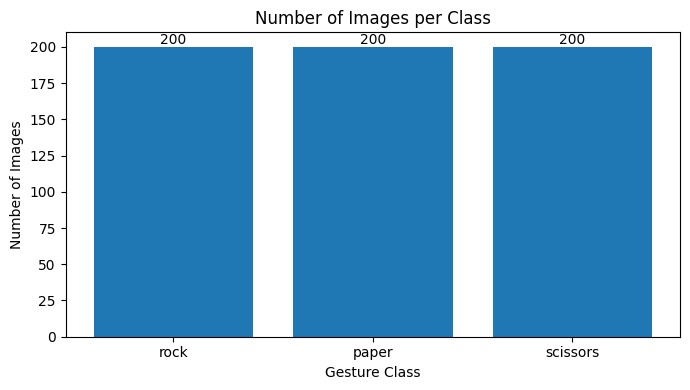

Interpretation:
The class counts are reasonably balanced by this simple count check.


In [15]:
# EDA Plot 1: Class distribution
if not metadata.empty:
    counts = metadata["class"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    plt.figure(figsize=(7, 4))
    bars = plt.bar(counts.index, counts.values)
    plt.title("Number of Images per Class")
    plt.xlabel("Gesture Class")
    plt.ylabel("Number of Images")
    plt.bar_label(bars)
    plt.tight_layout()
    plt.show()

    print("Interpretation:")
    max_count, min_count = counts.max(), counts.min()
    if min_count == 0:
        print("At least one class has no images. Add images before training.")
    elif max_count / min_count > 1.25:
        print("The class counts are noticeably imbalanced. Consider collecting more images for the smaller class(es).")
    else:
        print("The class counts are reasonably balanced by this simple count check.")


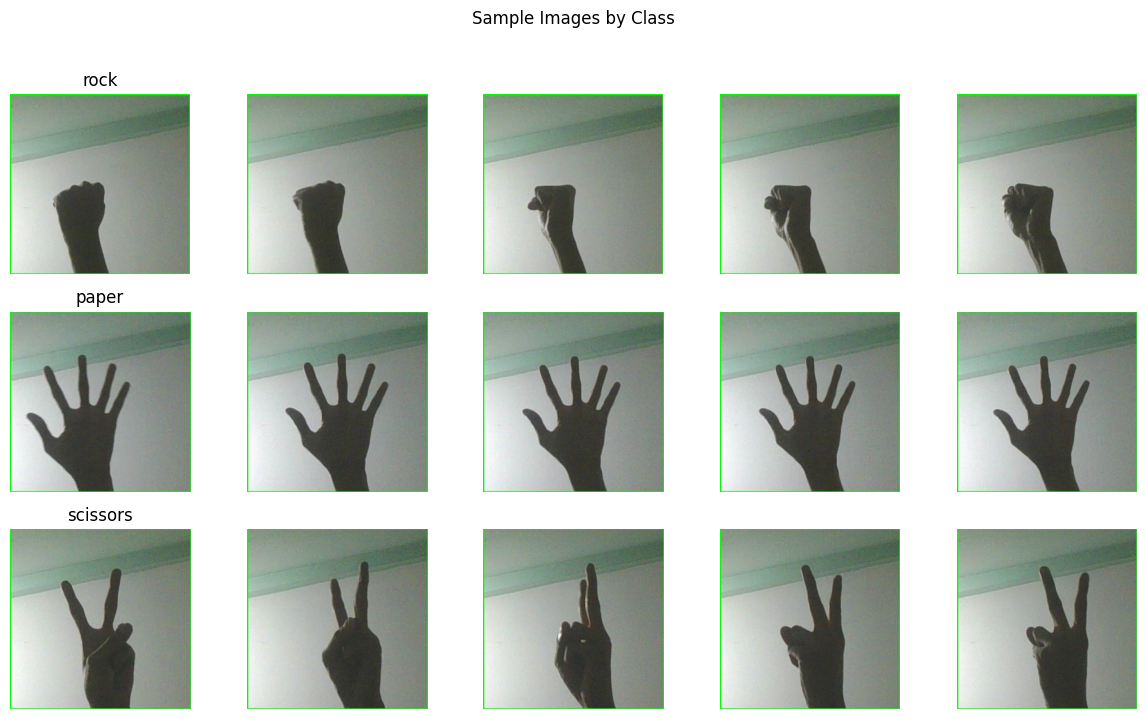

In [16]:
# EDA Plot 2: Example images from each class
if not metadata.empty:
    fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(12, 7))
    for row, class_name in enumerate(CLASS_NAMES):
        subset = metadata[metadata["class"] == class_name].head(5)
        for col in range(5):
            ax = axes[row, col]
            ax.axis("off")
            if col < len(subset):
                image_path = subset.iloc[col]["file"]
                with Image.open(image_path) as img:
                    ax.imshow(img.convert("RGB"))
                ax.set_title(class_name if col == 0 else "")
    fig.suptitle("Sample Images by Class", y=1.02)
    plt.tight_layout()
    plt.show()


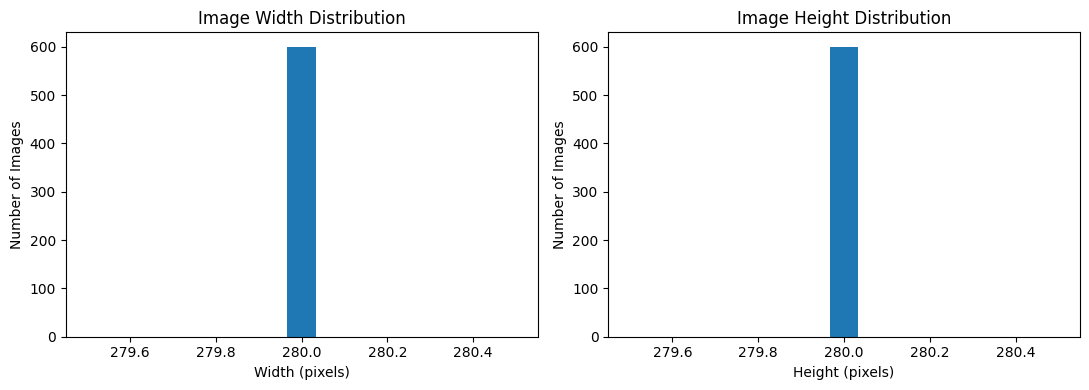

width             height             file_size_kb              
           min median  max    min median  max          min median    max
class                                                                   
paper      280  280.0  280    280  280.0  280        22.15  23.36  24.30
rock       280  280.0  280    280  280.0  280        21.27  21.94  22.91
scissors   280  280.0  280    280  280.0  280        21.67  22.39  23.19

In [17]:
# EDA Plot 3: Image width and height distributions
if not metadata.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(metadata["width"], bins=15)
    axes[0].set_title("Image Width Distribution")
    axes[0].set_xlabel("Width (pixels)")
    axes[0].set_ylabel("Number of Images")

    axes[1].hist(metadata["height"], bins=15)
    axes[1].set_title("Image Height Distribution")
    axes[1].set_xlabel("Height (pixels)")
    axes[1].set_ylabel("Number of Images")
    plt.tight_layout()
    plt.show()

    display(metadata.groupby("class")[["width", "height", "file_size_kb"]].agg(["min", "median", "max"]).round(2))


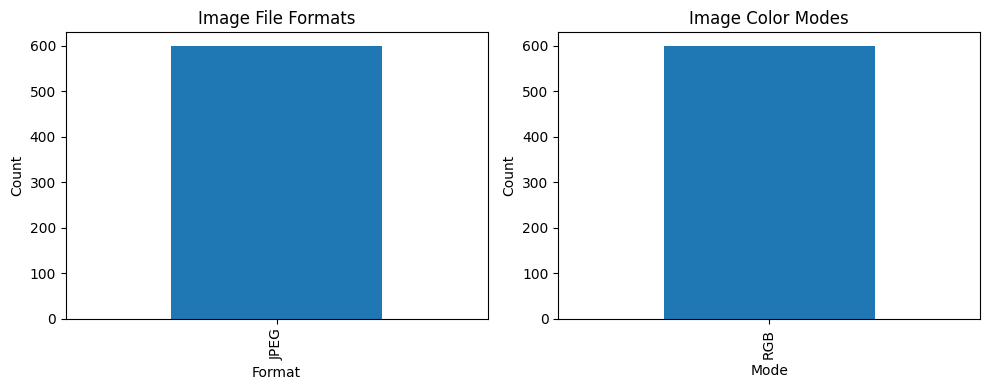

In [18]:
# EDA Plot 4: Image format and color-mode checks
if not metadata.empty:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    metadata["format"].value_counts().plot(kind="bar", ax=axes[0])
    axes[0].set_title("Image File Formats")
    axes[0].set_xlabel("Format")
    axes[0].set_ylabel("Count")
    metadata["mode"].value_counts().plot(kind="bar", ax=axes[1])
    axes[1].set_title("Image Color Modes")
    axes[1].set_xlabel("Mode")
    axes[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()
